# Jeu de dés et probabilité

Voilà un petit jeu de dès : vous avez 9 jetons numérotés de 1 à 9 et 2 dès à 6 faces. 

Vous lancez les dès et calculez la somme. Vous devez ensuite prendre autant de jetons que vous souhaitez tel que la somme des jetons soit égale à la somme des dès.

Par exemple, si vous tirez 3 et 4. Vous pouvez prendre au choix :

 * le jeton 7
 * les jetons 6 et 1
 * les jetons 5 et 2
 * les jetons 4 et 3
 * les jetons 4, 2, et 1
 
Puis vous rejouez jusqu'à ce que vous arriviez à une configuration où vous ne pouvez plus retirer de jeton. Le but est de terminer avec le moins de jeton possible.

On cherche à calculer le meilleur choix à faire à chaque étape.

## Un peu d'entrainement

On va commencer par des questions d'entrainements pour calculer et simuler des probabilités.

Les deux fonctions suivantes simulent des lancers de dès. La première lance un dé où chaque nombre est obtenu avec une probailité similaire, la seconde est un "dé pipé". Exécutez la cellule contenant les fonctions puis les exemples (plusieurs fois).

In [1]:
def deUniforme():
    """
    Retourne un nombre entre 1 et 6 de façon uniforme
    """
    return randint(1,6)

def dePipe():
    """
    Retourne un nombre entre 1 et 6 de façon non uniforme
    """
    i = randint(1,10)
    if i < 6:
        return i
    else:
        return 6

In [2]:
deUniforme()

5

In [3]:
dePipe()

6

Quelle est la probabilité d'obtenir 6 lors du lancé du dé pipé ?

Vous n'êtes pas sûr de votre réponse ? (vous devriez l'être...) Ce n'est pas grave, Vous pouvez compenser vos médiocres compétences en mathématiques par l'informatique et lancer une simulation. 

**Complétez la fonction suivante qui lance la simulation d'une fonction donnée et renvoie la liste des valeurs obtenues**.

In [6]:
def simulation(fonction, k):
    """
    Retourne la liste des valeurs de `k` appels successifs de `fonction`
    
    INPUT :
    
        - `fonction` une fonction python qui ne prend pas d'argument et renvoie une variable aléatoire
        - `k` un entier (le nombre d'appels à effectuer)
    """
    return [fonction() for i in range(k)]

In [7]:
# on vérifie que vous avez lancez le bon nombre de tests
assert len(simulation(deUniforme,100)) == 100

In [8]:
# on vérifie que vous obtenez bien le bon ensemble de valeur
assert set(simulation(deUniforme,100)) == {1,2,3,4,5,6}

/opt/conda/lib/python3.9/site-packages/matplotlib/__init__.py:152: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  if LooseVersion(module.__version__) < minver:
/opt/conda/lib/python3.9/site-packages/setuptools/_distutils/version.py:351: DeprecationWarning: distutils Version classes are deprecated. Use packaging.version instead.
  other = LooseVersion(other)


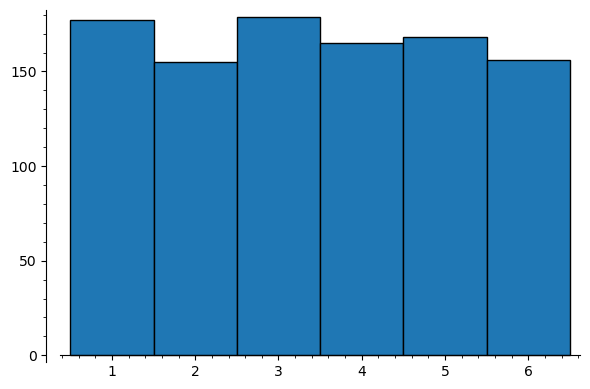

In [9]:
# vous pouvez afficher une simulation sous forme d'un histogramme
histogram(simulation(deUniforme,1000), bins = [i+0.5 for i in range(0,7)])

**Affichez l'histogramme de la fonction `dePipe`**

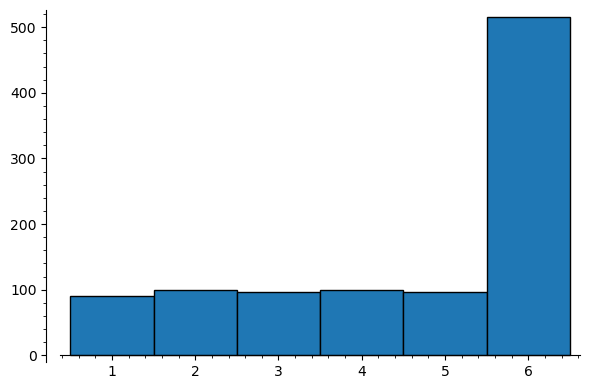

In [10]:
histogram(simulation(dePipe,1000), bins = [i+0.5 for i in range(0,7)])

Il est possible d'afficher l'histogramme pour que les valeurs en ordonnées correspondent non pas au nombre d'occurrences mais à la distribution de probabilité obtenue expérimentalement. Par exemple, vous pouvez lire ci-dessous que toutes les valeurs de `deUniforme` apparaissent avec une probabilité légèrement supérieure à $0.15$ : la probabilité théorique est en effet $\frac{1}{6} = 0.16666\dots$.

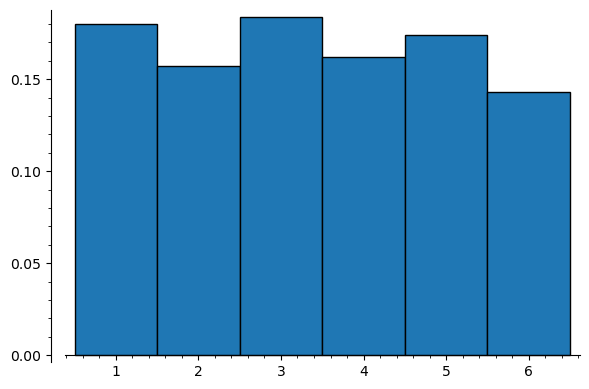

In [11]:
histogram(simulation(deUniforme,1000), bins = [i+0.5 for i in range(0,7)], density = True)

**Affichez l'histogramme de la fonction `dePipe` avec la probabilité en ordonnée et vérifiez que le résultat correspond à la probabilité théorique.**

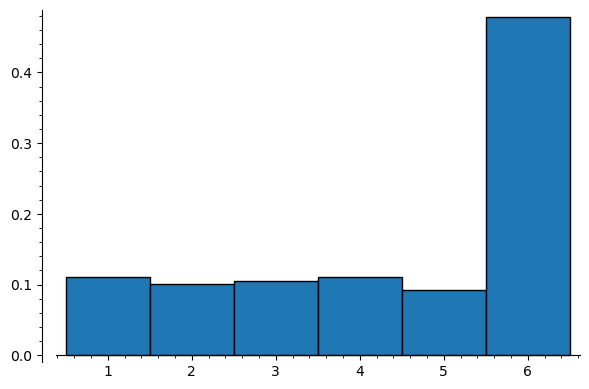

In [12]:
histogram(simulation(dePipe,1000), bins = [i+0.5 for i in range(0,7)], density = True)

Par la suite, on souhtaite pouvoir calculer cette probabilité évaluée sans passer par l'histogramme. **Complétez la fonction suivante qui lance une simulation d'une fonction aléatoire et évalue la probabilité d'obtenir une valeur donnée.** 

Le résultat étant une valeur approchée, on souhaite qu'il soit donnée sous forme décimale (nombre à virgule) et non comme une fraction. On peut utiliser la méthode `n()` des nombres de Sage

In [13]:
# exemple
a = 1/2
print(a)
print(a.n())

1/2
0.500000000000000


In [16]:
def evalProba(fonction, n, k):
    """
    Evalue la probabilité que `fonction()` soit égale à `n` avec `k` lancés.
    
    INPUT:
    
        - `foncion` une fonction python
        - `n` le résultat testé
        - `k` le nombre de tests effectués
        
    OUTPUT : un nombre float, la probabibilité évaluée
    """
    
    l = simulation(fonction, k)
    return (l.count(n)/k).n()

In [17]:
evalProba(deUniforme,6,1000)

0.185000000000000

In [18]:
# on vérifie que vous renvoyez bien une probabilité
assert evalProba(deUniforme,6,100) >= 0
assert evalProba(deUniforme,6,100) <= 1

In [19]:
# on vérifie que le résultat n'est pas une fraction
assert(type(evalProba(deUniforme,6,1000)) != sage.rings.rational.Rational)

On utilise la fonction suivante pour comparer la probabilité évaluée avec la probabilité théorique.

In [20]:
def cmpProba(p1, p2):
    """
    Renvoie True si la différences entre les deux nombres `p1` et `p2` est inférieure à 0.05
    """
    return abs(p1 - p2) <= 0.05

In [21]:
# on vérifie les probas évaluée pour deUniforme et dePipe
assert cmpProba(evalProba(deUniforme, 6, 1000), 1/6)
assert cmpProba(evalProba(deUniforme, 3, 1000), 1/6)
assert cmpProba(evalProba(dePipe, 6, 1000), 1/2)
assert cmpProba(evalProba(dePipe, 3, 1000), 1/10)

**Complétez la fonction suivante telle que la propabilité d'obtenir 6 soit égale à $\frac{3}{8}$ tandis que la probabilité d'obtenir chacun des nombres de 1 à 6 est $\frac{1}{8}$.**

In [22]:
def dePipe2():
    """
    Retourne un entier entre 1 et 6 de façon non uniforme
    """
    r = randint(1,8)
    if(r>=6):
        return 6
    else:
        return r

In [23]:
dePipe2()

5

In [24]:
# on vérfifie que la fonction renvoie bien un entier entre 1 et 6
assert all(dePipe2() in {1,2,3,4,5,6} for k in range(100))

**Affichez l'histogramme de votre fonction avec les probabilités en ordonnée**.

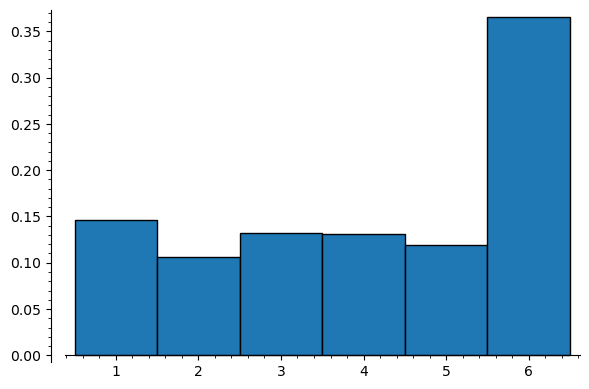

In [25]:
histogram(simulation(dePipe2,1000), bins = [i+0.5 for i in range(0,7)], density = True)

In [26]:
# on vérifie que les probas correspondent
assert all(cmpProba(evalProba(dePipe2, i, 1000), 1/8) for i in range(1,6))
assert cmpProba(evalProba(dePipe2, 6, 1000), 3/8)

**Ecrivez une fonction `sommeDes` qui simule le lancer de deux dès uniforme et en calcule la somme**.

In [32]:
def sommeDes():
    """
    Simule le lancer de deux dés uniforme et en renvoie la somme.
    """
    return deUniforme()+deUniforme()


In [33]:
sommeDes()

11

In [34]:
# vérifions que la foncion renvoie bien un entier entre 2 et 12
E = set(range(2,13))
assert(all(sommeDes() in E for k in range(100)))

**Affichez l'histogramme des probabilités d'une simulation de sommeDes sur 1000 lancés** (Attention, il faut changer l'argument `bins` qui correspond aux barres de séparation)

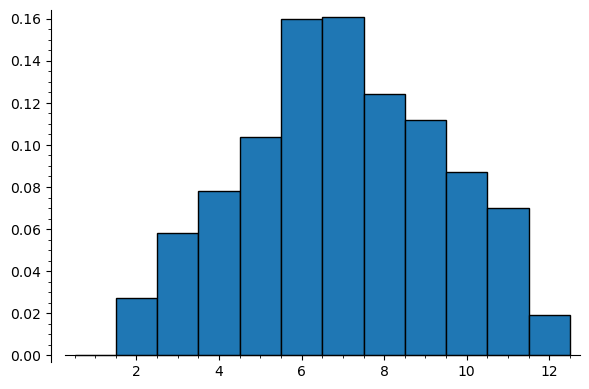

In [36]:
histogram(simulation(sommeDes,1000), bins = [i+0.5 for i in range(0,13)], density = True)

**Complétez la fonction suivante qui calcule la probabilité *exacte* que la somme de deux dés uniforme soit égale à n.** Cette fois, vous devez faire le calcul mathématique, pas une simulation.

In [37]:
def proba_sommeDes(n):
    """
    Renvoie la probablité que la somme de deux dés soit égale à `n`
    """
    L = [i+j for i in range(1,7) for j in range(1,7)]
    return L.count(n)/36
    

In [38]:
# quelques tests de base
assert proba_sommeDes(0) == 0
assert proba_sommeDes(1) == 0
assert proba_sommeDes(2) == 1/36
assert proba_sommeDes(3) == 1/18
assert proba_sommeDes(12) == 1/36

In [39]:
proba_sommeDes(4)

1/12

In [40]:
# vérifions que la somme des probas est égale à 1
assert sum(proba_sommeDes(v) for v in range(2,12))

In [41]:
# vérifions que la probabilité exacte est égale à la probabilité évaluée
assert all(cmpProba(evalProba(sommeDes, v, 1000), proba_sommeDes(v)) for v in range(2,13))

## Et maintenant, le jeu

on va représenter la liste des jetons disponible par un tuple python `(1,2,3,4,5,6,7,8,9)`. On vous donne la fonction suivante qui calcule la liste des configurations possibles après avoir retiré les jetons correspondant à une somme de deux dés.

In [42]:
def choixPossible(jetons, somme_des):
    """
    Renvoie les configurations possible en retirant des jetons à la configuration `jetons` dont la somme est `sommeDes`
    """
    # conditions d'arret
    if len(jetons) == 0:
        if somme_des == 0:
            return [tuple()] # la configuration vide
        else:
            return [] # pas de configuration possible
    if somme_des < 0:
        return [] # pas de configuration possible
    # récursion
    R = [] # ma liste résultat
    dernier = jetons[-1] # le dernier jeton de la configuration
    # soit je le choisis
    for choix in choixPossible(jetons[:-1], somme_des - dernier): # jeton[:-1] est la liste sans le dernier élément
        R.append(choix) 
    # soit je ne le choisis pas
    for choix in choixPossible(jetons[:-1], somme_des): 
        R.append(choix + (dernier,)) 
    
    return R

Par exemple, si j'ai les jetons `(1,3,4,8)` et que je tire 4, je peux

* choisir $1$ et $3$ et obtenir `(4,8)`
* choisir $4$ et obtenir `(1,3,8)`

In [43]:
choixPossible((1,3,4,8), 4)

[(1, 3, 8), (4, 8)]

In [44]:
choixPossible((1,2,3,4,5,6,7,8,9), 7)

[(1, 2, 3, 4, 5, 6, 8, 9),
 (2, 3, 4, 5, 7, 8, 9),
 (1, 3, 4, 6, 7, 8, 9),
 (1, 2, 5, 6, 7, 8, 9),
 (3, 5, 6, 7, 8, 9)]

**Notre but** est de calculer pour **chaque configuration** quel est le *score moyen* (espérance) que l'on peut réaliser si on "joue bien". On utilisera un *dictionnaire* python qui à chaque configuration associe son espérance de score.

Comme j'ai fait le TP avant vous, j'ai **déjà** calculé ce dictionnaire dont voici les premières valeurs.

In [45]:
scoreMoyen = {
 (): 0,
 (1,): 1,
 (3,): 17/18,
 (2,): 35/36,
 (1, 2): 67/36,
 (1, 3): 16/9,
 (2, 3): 137/81,
 (1, 2, 3): 883/432,
}

In [46]:
# la configuration (2,3) permet d'obtenir un score moyen de 1.69 = 137/81
scoreMoyen[(2,3)].n()

1.69135802469136

Le calcul du dictionnaire étant difficile, nous le réaliserons plus tard. Pour l'instant, on va travailler avec le début de dictionnaire que j'ai calculé pour vous.

Imaginez que vous jouer : vous lancez les deux dés, il vous reste certains jetons et vous devez choisir quels jetons supprimer. C'est le but de la fonction ci-dessous : elle parcourt les différentes configurations possible grâce à ``choixPossible`` et utilise le dictionnaire pour choisir la nouvelle configuration qui **minimise** le score.


**Compléter la fonction ci-dessous qui prend en paramètre la configuration actuelle et la valeurs des dés et qui retourne le meilleur choix possible.** (C'est-à-dire le choix possible qui minimise le score).

In [50]:
def meilleurChoix(jetons, des, scoreMoyen):
    """
    Renvoie le meilleur choix de nouvelle configuration possible en partant de `jetons` avec les des `des` d'après `scoreMoyen`
    
    INPUT:
    
        - jetons, un tuple d'entier correspondant à une configuration de jeton
        - des, un entier en 1 et 12
        - scoreMoyen, un dictionnaire python de configurations / scores moyens
        
    OUPUT : la meilleur nouvelle configuration que l'on peut jouer.
    
    S'il n'y a aucun choix possible, on renvoie `None`
    """
    jFutur = choixPossible(jetons, des)
    res = None
    score = -1
    for c in jFutur :
        if(c in scoreMoyen):
            scoreTemp = scoreMoyen[c]
            if(scoreTemp<score or score < 0):
                res = c
                score = scoreTemp
    return res

In [51]:
meilleurChoix((1,2,3),4, scoreMoyen)

(2,)

In [52]:
# vérifions
assert meilleurChoix((1,2,3),3, scoreMoyen) == (3,)
assert meilleurChoix((2,),2, scoreMoyen) == tuple()
assert meilleurChoix((2,),4, scoreMoyen) is None

Le but est maintenant de calculer vous même le dictionnaire ``scoreMoyen`` dont on vous avait donné un exemple. Pour cela, la première étape est de calculer **toutes les configurations possibles**, c'est-à-dire tous les sous ensemble de jetons de $(1, \dots, n)$, il y en a $2^n$. La fonction ressemble à `choix_disponible` en plus facile car on n'a pas à s'occuper de `somme_des`, on vous la donne ci-dessous.

In [53]:
def toutesConfigurations(jetons):
    """
    Renvoie toutes les configurations possible de l'ensemble `jetons`
    """
    # condition d'arret
    if len(jetons) == 0:
        return [tuple()] # lorsque l'ensemble est vide, il n'y a qu'une seule solution
    # récursion
    R = [] # la liste qui doit contenir toutes les configuration possible
    dernier = jetons[-1] # le dernier jeton
   

    for conf in toutesConfigurations(jetons[:-1]):
        R.append(conf)
        R.append(conf + (dernier,))
    
    return R

In [54]:
toutesConfigurations((1,2,3))

[(), (3,), (2,), (2, 3), (1,), (1, 3), (1, 2), (1, 2, 3)]

In [55]:
# vérifions les petits cas
assert toutesConfigurations(tuple()) == [tuple()]
assert toutesConfigurations((1,)) == [tuple(), (1,)]

In [56]:
# vérifions les cas plus gros
assert len(toutesConfigurations((1,2,3))) == 2**3
assert len(toutesConfigurations((1,2,3,4,5,6,7,8,9))) == 2**9

On va maintenant écrire la fonction principale du programme. Le but est d'associer à chaque configuration **l'espérance** du score que l'on peut réaliser si on fait **le meilleur choix possible** à chaque étape. On va enregistrer cette espérance dans un **dictionnaire python** : les clés sont les configurations et les valeurs les esperances.

Rappelons que pour une configuration donnée, l'espérance du score est le "score moyen" que l'on peu atteindre, c'est à dire $\sum (s \times p(s))$ sommé sur l'ensemble des scores atteignables où $s$ est le score et $p(s)$ la probabilité d'obtenir ce score à partir de la configuration.

Concrètement, si j'ai la configuration vide. Alors, quels que soient les dés tirés, je ne peux plus retirer de jeton : la partie est terminée et j'obtiens le score de 0 avec probabilité 1 : mon espérance est 0. 

S'il me reste les jetons $1$ et $2$. Alors, 

* je peux tirer $3$ avec probablité $\frac{1}{18}$ qui me permet de retirer les jetons 1 et 2 et la partie s'arrète avec score $0$ (il ne me reste plus de jetons)
* je peux tirer $2$ avec probabilité $\frac{1}{36}$ qui force à retirer le jeton 2, puis la partie s'arrète avec score $1$ (il me reste un jeton)
* si je tire autre chose, la partie s'arrête avec un score $2$ (il me reste deux jetons)

L'espérance (le score moyen) est donnée par $0 \times \frac{1}{18} + 1 \times \frac{1}{36} + 2 \times \frac{33}{36} = \frac{67}{36} \approx 1.861$.

L'algorithme fonctionne de cette façon. On va calculer le dictionnaire `scoreMoyen` au fur et à mesure en partant des configurations contenant peu de jetons (c'est l'ordre des configurations données par `toutesConfigurations`). Ca s'appelle de la programmation dynamique : les calculs pour les petites configurations sont utilisés pour les configurations plus grosses.

On parcourt l'ensemble des configuration possible. Pour chaque configuration $c$ on calcule les choix possibles du joueur pour chaque somme de dés $v$ :

* Cas 1 : s'il n'y a plus de choix pour la valeur $v$ on rajoute `fonctionScore(c) * proba_sommeDes(v)` à la valeur `scoresMoyen[c]` dans le dictionnaire.
* Cas 2 : s'il reste des choix, on utilise les valeurs précédentes du dictionnaire pour trouver **le meilleur choix possible** $c2$ et on ajoute `scoreMoyen[c2] *  proba_sommeDes(v)` à `scoreMoyen[c]`.

**En vous aidant de ces indications, compléter la fonction suivante**.

Remarques : 

1. vous devez utiliser les fonctions `proba_sommeDes`, `toutesConfigurations` ainsi que `meilleurChoix`.
2. pour calculer le meilleur choix, on va envoyer en paramètre le dictionnaire qu'on a partiellement calculé sur des configurations plus petites. C'est ce qu'on appelle de la *programmation dynamique*.

In [61]:
def scoreLongueur(jetons):
    """
    Renvoie le score associé à une configuration de jetons où le score est le nombre de jetons restant
    """
    return len(jetons)

def esperanceScores(jetons, fonctionScore):
    """
    Renvoie un dictionnaire associant à chaque configuration de `jetons` l'espérance du score  associée 
    
    INPUT:
    
        - `jetons` les jetons de départ du jeu
        - `fonctionScore` une fonction python calculant le score d'une configuration
    """
    scoreMoyen = {} # initialisation du dictionnaire : au début, il est vide
    
    
    for c in toutesConfigurations(jetons):
        # on va calculer le score moyen de c (on a déjà calculé toutes les configurations plus petites)
        scoreMoyen[c] = 0 
        for v in range(2,13):
            # on parcourt toutes les valeurs de dés possible
            # à vous :
            # - utilisez meilleurChoix pour trouver la meilleure solution en fonction de c, v et scoreMoyen
            # - Soit il n'y a pas de meilleur choix et on est dans le Cas 1 de l'énoncé
            # - Soit il y a un meilleur choix et on est dans le Cas 2 de l'énoncé
            
            meiChoix = meilleurChoix(c, v, scoreMoyen)
            if(meiChoix == None):
                scoreMoyen[c] += fonctionScore(c) * proba_sommeDes(v)
            else:
                scoreMoyen[c] += scoreMoyen[meiChoix] *  proba_sommeDes(v)
                
    return scoreMoyen

In [62]:
esperanceScores((1,2,3), scoreLongueur)

{(): 0,
 (3,): 17/18,
 (2,): 35/36,
 (2, 3): 137/81,
 (1,): 1,
 (1, 3): 16/9,
 (1, 2): 67/36,
 (1, 2, 3): 883/432}

In [63]:
# testons
assert esperanceScores((1,2,3), scoreLongueur) == { (): 0, (1,): 1, (3,): 17/18, (2,): 35/36, (1, 2): 67/36, (1, 3): 16/9, (2, 3): 137/81, (1, 2, 3): 883/432,}

In [64]:
esperanceScores((1,2,3,4), scoreLongueur)

{(): 0,
 (4,): 11/12,
 (3,): 17/18,
 (3, 4): 41/27,
 (2,): 35/36,
 (2, 4): 347/216,
 (2, 3): 137/81,
 (2, 3, 4): 2053/1296,
 (1,): 1,
 (1, 4): 61/36,
 (1, 3): 16/9,
 (1, 3, 4): 767/432,
 (1, 2): 67/36,
 (1, 2, 4): 7/4,
 (1, 2, 3): 883/432,
 (1, 2, 3, 4): 61571/46656}

In [65]:
# testons encore
scoreMoyen = esperanceScores((1,2,3,4,5,6,7,8,9), scoreLongueur)
assert scoreMoyen[(1,2,3,4,5,6,7,8,9)] == 43012899935/19591041024

Vous avez maintenant l'outil parfait pour *tricher* à ce jeu avec vos amis : il vous suffit d'avoir votre ordinateur à portée de main, de calculer le dictionnaire puis de demander à chaque lancé de dés quel est le meilleur coup à jouer... Vous obtiendrez un score moyen de :

In [66]:
scoreMoyen[(1,2,3,4,5,6,7,8,9)].n()

2.19553927135914

On va maintenant vérfier avec des simulations de partie qu'il est plus intéressant de jouer de cette façon que de jouer "bêtement" au hasard.

On vous donne deux fonctions de similuations de jeu : les fonctions simulent une partie entière en tirant des dés au hasard, elles renvoient le score obtenu.

La première fonction fait le meilleur choix à chaque étape en fonction du dictionnaire `scoreMoyen`

In [67]:
def simulationMeilleurChoix(jetons, scoreMoyen):
    """
    Effecute une simulation de partie où l'on fait le meilleur choix (selon `scoreMoyen`) à chaque étape
    
    INPUT :
    
        - jetons, la configuration de départ
        - scoreMoyen, les scores moyens calculés précédemment
        
    OUTPUT: le score final obtenu
    """
    v = sommeDes()
    m = meilleurChoix(jetons, v, scoreMoyen)
    if m is None:
        return len(jetons)
    return simulationMeilleurChoix(m, scoreMoyen)

In [68]:
simulationMeilleurChoix((1,2,3,4,5,6,7,8,9), scoreMoyen) # le score obtenu (change à chaque fois que vous exécutez la ligne)

3

La seconde fonction fait un choix au hasard à chaque fois en utilisant la fonction `choixAuHasard`.

In [69]:
def choixAuHasard(jetons, des):
    """
    Renvoie un choix "au hasard" parmis les choix de nouvelle configuration possible en partant de `jetons` avec les des `des`
    
    INPUT:
    
        - jetons, un tuple d'entier correspondant à une configuration de jeton
        - des, un entier en 1 et 12
        
    OUPUT : une nouvelle configuation autorisée prise au hasard (uniformément)
    
    S'il n'y a aucun choix possible, on renvoie `None`
    """
    minc = None
    C = choixPossible(jetons, des)
    if len(C) == 0:
        return None
    i = randint(0,len(C)-1)
    return C[i]

def simulationAuHasard(jetons):
    """
    Effecute une simulation de partie où l'on fait un choix au hasard à chaque étape
    
    INPUT :
    
        - jetons, la configuration de départ
        
    OUTPUT: le score final obtenu
    """
    v = sommeDes()
    m = choixAuHasard(jetons, v)
    if m is None:
        return len(jetons)
    return simulationAuHasard(m)

In [70]:
simulationAuHasard((1,2,3,4,5,6,7,8,9)) # le score obtenu

2

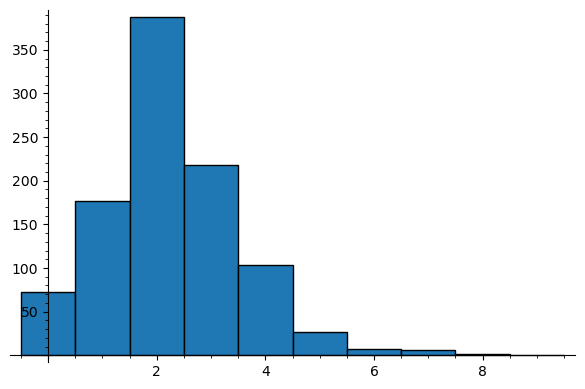

In [71]:
# on affiche l'histogramme sur 1000 parties pour le "meilleur choix"
# (doit avoir beaucoup de scores au niveau du 2)
histogram([simulationMeilleurChoix((1,2,3,4,5,6,7,8,9), scoreMoyen)  for i in range(1000)], bins = [i+0.5 for i in range(-1,10)] )

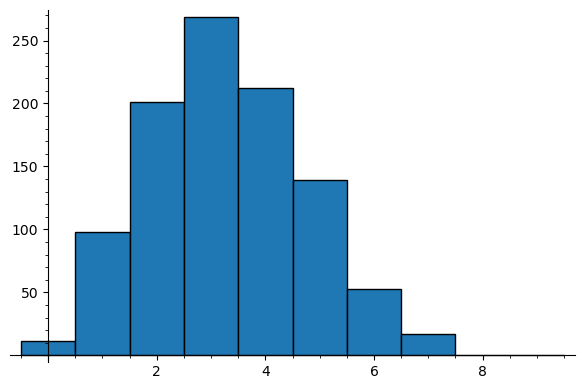

In [72]:
# on affiche l'histogramme sur 1000 parties pour le choix au hasard
# (doit avoir beaucoup de scores au niveau du 3)
histogram([simulationAuHasard((1,2,3,4,5,6,7,8,9))  for i in range(1000)], bins = [i+0.5 for i in range(-1,10)] )